<a href="https://colab.research.google.com/github/PioPio31/AnaliticaDeDatos_Equipo1/blob/main/Practica3_U3/Actividad3_U3_PaolaIbarra23111420.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Datos Alumno**

# * **Nombre**: Paola Ibarra Ordaz
# * **No control**: 23111420

#### **En esta actividad trabajarás con datos históricos del precio de mercado de la acción de alguna de las grandes compañías como Nvidia, Tesla, Google.**

Sigue los siguientes pasos para descargar los datos del problema:

    Ir a la página de Yahoo!-Finance: https://finance.yahoo.com/

En el buscador de dicha página pon las iniciales de la compañía deseada. Deberás seleccionar alguna de las siguientes compañías: AAPL, NVDA, TSLA, GOOG, AMZN o MSFT.

Seleccionar la pestaña "Historical Data".

Pulsa "Download" para descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.



# **En esta Actividad se trabajará con los datos historicos del precio de mercado de la acción, Compañia Apple (AAPL).**

# **0 - Preparando los datos ORIGINALES**

In [ ]:
# Omitamos los Warnings por el momento:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
#!pip freeze   # Si deseas verificar qué librerías y versiones ya tiene google-Colab preinstaladas,
               # en particular "prophet" que usaremos en este ejercicio.

In [ ]:

#Libreria para obtener el conjunto de datos
import yfinance as yf

#Para manipular datos
import numpy as np
import pandas as pd

#Para graficar
import matplotlib.pyplot as plt

#Error cuadratico medio
from sklearn.metrics import mean_squared_error
import math

#Para aplicar escalamiento de datos [0,1]
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # gráficos de autocorrelación

#A) **Descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.**

In [ ]:
#Escribimos las iniciales de la compañia con la que deseemos trabajar. En esta ocasión trabajare con Tesla

ticker_symbol = 'AAPL'                           # selecciona las iniciales de la compañía deseada.
data = yf.download(ticker_symbol, period='5y')   # Se indica el período de 5 años y descargamos.
data.to_csv('historical_data.csv')               # Guardamos los datos


[*********************100%***********************]  1 of 1 completed


In [ ]:
data.head() #muestra los primeros 5 registros del conjunto de datos

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2021-11-15,146.407959,148.242944,145.851602,146.769094,59222800
2021-11-16,147.384003,147.862274,145.763751,146.349389,59256200
2021-11-17,149.814392,151.288227,147.374259,147.384015,88807000
2021-11-18,154.089478,154.870323,149.384910,150.029109,137827700
2021-11-19,156.705292,157.164038,152.781555,153.874729,117305600


In [ ]:
#convierte a dataframe
path = 'historical_data.csv'
df = pd.read_csv(path, header=2)
df.columns = ['Date', 'Close', 'High', 'Low', 'Open', 'Volume']
df.head()

,Date,Close,High,Low,Open,Volume
0,2021-11-15,146.407959,148.242944,145.851602,146.769094,59222800
1,2021-11-16,147.384003,147.862274,145.763751,146.349389,59256200
2,2021-11-17,149.814392,151.288227,147.374259,147.384015,88807000
3,2021-11-18,154.089478,154.870323,149.384910,150.029109,137827700
4,2021-11-19,156.705292,157.164038,152.781555,153.874729,117305600


In [ ]:
df.info()   # Verifica detalles del conjunto de datos a utilizar
            # El dataframe cuenta con 1254 registros
            # 6 columnas las cuales son: Date, Close, High, Low, Open, Volume
            # Variable Date, tipo Object -> se cambiará a tipo Fecha

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1255 entries, 0 to 1254
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1255 non-null   object 
 1   Close   1255 non-null   float64
 2   High    1255 non-null   float64
 3   Low     1255 non-null   float64
 4   Open    1255 non-null   float64
 5   Volume  1255 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 59.0+ KB


#**B)Utiliza solamente los datos de la columna "Close" en esta actividad.**

In [ ]:
# Renombremos de manera estándar las columnas de fechas y valores de la
# serie de tiempo, donde además la fecha la trasnformamos a tipo datetime:

df = df.drop(columns=['High','Low','Open','Volume']) #Elimina columnas que no se requieren
df = df.rename(columns={'Close':'y'})                    #Columna Close, renombramos por y
df['Date'] = pd.to_datetime(df['Date'])                      #Convertimos variable Date de tipo Object a Datetime
df.head()                                                    #Muestra primeros 5 registros para visualizar el cambio

,Date,y
0,2021-11-15,146.407959
1,2021-11-16,147.384003
2,2021-11-17,149.814392
3,2021-11-18,154.089478
4,2021-11-19,156.705292


In [ ]:
df.info() #Creación de un nuevo df, el cual consta de 2 columnas, las cuales son:
          #Variable Date -> de tipo datetime64, nos ayuda a representar un rango de fechas muy amplio con presición nanosegundos
          #Variable 'Close' -> fue renombrada por 'y' de tipo flotante,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1255 entries, 0 to 1254
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1255 non-null   datetime64[ns]
 1   y       1255 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.7 KB


En particular datetime64[ns] nos ayuda a representar un rango de fechas muy amplio con precisión de nanosegundos.

### **Agreguemos los ajustes usuales en Series de tiempo:**

In [ ]:
# Hagamos una copia del DataFrame df con índices temporales:

df_temp = df.copy()                     #Genera copia del df originar en nueva variable temporal de nombre: df_temp
df_temp.set_index('Date', inplace=True) #se establece como indice Variable Date,
                                        #parametro inplace=True, es para guardar los cambios
df_temp.head()                          #visualizar los cambios

,y
Date,
2021-11-15,146.407959
2021-11-16,147.384003
2021-11-17,149.814392
2021-11-18,154.089478
2021-11-19,156.705292


In [ ]:
#Muestra información sobre numero total de registros y columnas como estan conformados el df original (df) y el df temporal (df_temp)

print("DataFrame Original:\n ")
print(df.shape)      #Conformado por 1258 registros y 2 columnas (Date, y)

print("\nDataFrame Temporal:\n")
print(df_temp.shape) #Conformado por 1258 regsitros y 1 columna (y), Variable Date pase a ser indice

DataFrame Original:
 
(1255, 2)

DataFrame Temporal:

(1255, 1)


https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html

In [ ]:
# Ajustemos la frecuencia de los índices, para que el modelo tenga información del período en que
# se encuentran los datos:

df_temp.index =df_temp.index.tz_localize(None) #Para quitar zona horaria
df_temp.index


DatetimeIndex(['2021-11-15', '2021-11-16', '2021-11-17', '2021-11-18',
               '2021-11-19', '2021-11-22', '2021-11-23', '2021-11-24',
               '2021-11-26', '2021-11-29',
               ...
               '2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-09', '2026-11-10', '2026-11-11',
               '2026-11-12', '2026-11-13'],
              dtype='datetime64[ns]', name='Date', length=1255, freq=None)

-----------------------------------------------------------------------------
**Se puede observar que la ejecución se esta línea de código indica 'freq=None', por lo cual tendremos que definir un tipo de frecuencia (ya sea por dias, meses, años). La cual se definirá en el siguiente segmento de código que se muestra a continuación:**

-----------------------------------------------------------------------------

Para las opciones de "freq" ver la tabla que viene en esta liga:

https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases

In [ ]:
# Especifiquemos entonces que nuestros datos están registrados con una frecuencia mensual
# al inicio del mes (cada día 01 de cada mes):

df_temp = df_temp.resample('B').asfreq()#Define frecuencia B -> frecuencia del día de actividad
df_temp.index

DatetimeIndex(['2021-11-15', '2021-11-16', '2021-11-17', '2021-11-18',
               '2021-11-19', '2021-11-22', '2021-11-23', '2021-11-24',
               '2021-11-25', '2021-11-26',
               ...
               '2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-09', '2026-11-10', '2026-11-11',
               '2026-11-12', '2026-11-13'],
              dtype='datetime64[ns]', name='Date', length=1305, freq='B')

#**C)Investiga el significado de esta columna Adj-Close e inclúyelo en tu reporte del Jupyter-Notebook.**

###Investigación

-------------------------------------------------------------------------
¿Qué es el Cierre Ajustado?

Adj Close es una columna Clave dentro de los datos historicos . El **Precio Ajustado de cierre**, se apoya de dividendos y splist de acciones, que afectan el precio de la acción.

Es una versión ajustada del Precio de Cierre de una acción, después de los ajustes para todas las distribuciones de splits y dividendos aplicables, los cuales se definen a continuación:

 * **Dividendos**, Aqui es cuando la empresa distribuye dividendos a sus accionistas. El dividendo se "resta" del precio de la acción para representar el valor real de la acción después del pago realizado.

* **Splits(Divisiones de Acciones)**, Aqui es cuando el precio de la acción se ajusta para reflejar la nueva cantiad de acciones en circulación. Aumenta el número de acciones de circulación, pero la capitalización no cambia

##Importancia del Adj Close

El Adj Close, es muy importante ya que gracias a el se puede visualizar de mejor la manera la evolución del valor de la acción que se ha tenido a lo largo del tiempo. Siendo muy útil al momenteo de realizar análisis de rendimiento y asi lograr obtener una visipon más clara de cómo se ha comportado una acción dentro del mercado por un periodo de tiempo

De igual manera también es muy útil para realizar cálculos más precisos, si se desea cálcular el rendimiento total de una acción o retornos de una inversión en un cierto periodo, ya que por otro lado si se hace uso unicamente de "close" sin el ajuste, puede existir sesgo en el análisis.

--------------------------------------------------------------------

#**D)Divide los datos en Train y Test, donde Test serán los últimos 20 precios de mercado de la compañía que seleccionaste**

In [ ]:
df_temp=df_temp.ffill() #para rellenar datos faltantes NaN
datos_nan=df_temp[df_temp.isna().any(axis=1)] #para verificar existencia datos faltantes
#print(datos_nan)

In [ ]:
# Particionemos en entrenamiento y prueba como DataFrames de Pandas:
train = df_temp.iloc[0:-20,:] # Selecciona todos los registros, excepto últimos 20
test = df_temp.iloc[-20:,:]   # Seleccionamos los datos del últimoS 20 registros para predicción de Test.

In [ ]:
test.head()  #muestra registros del test

,y
Date,
2026-10-19,342.679626
2026-10-20,339.242249
2026-10-21,343.728821
2026-10-22,347.955627
2026-10-23,347.466003


In [ ]:
datos_nan=train[train.isna().any(axis=1)]
print(datos_nan) #verificamos que no existan datos faltantes NaN en Entrenamiento (train)

datos_nan=test[test.isna().any(axis=1)]
print(datos_nan) #verificamos que no exista datos faltantes NaN en Pueba (test)

Empty DataFrame
Columns: [y]
Index: []
Empty DataFrame
Columns: [y]
Index: []


### Interpretación de los datos de entrenamiento y prueba (AAPL)
El conjunto de datos corresponde a los precios de cierre de Apple (AAPL) de aproximadamente cinco años. Se conservaron únicamente las columnas de fecha y precio de cierre (y). Para preparar la serie, se estableció la fecha como índice y se utilizó la frecuencia de días hábiles (B); los espacios sin registro se completaron con el último precio disponible mediante ffill().

La partición se realizó dejando los últimos 20 registros para prueba (test) y el resto para entrenamiento (train). De esta manera, el modelo se construirá con los datos anteriores y podrá evaluarse con observaciones posteriores, evitando utilizar los registros de prueba durante el entrenamiento.

En las comprobaciones de la celda anterior, ambos conjuntos muestran DataFrames vacíos al buscar valores faltantes (NaN). Esto indica que, después del relleno de datos, no se identificaron valores faltantes en train ni en test.

In [ ]:
train.shape #Entrenamiento conformado por 1284 registros y 1 columna

(1285, 1)

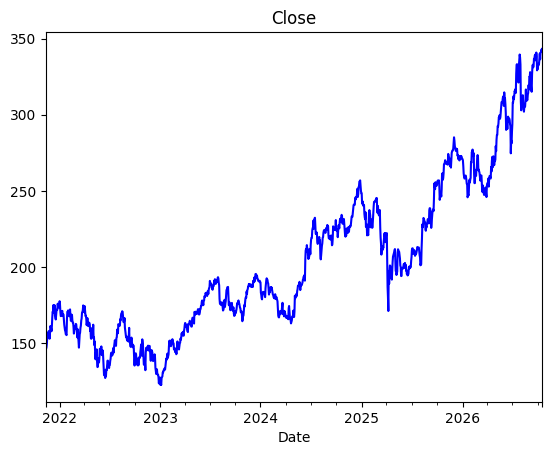

In [ ]:
# Gráfico con la periodicidad anual:
train['y'].plot(title='Close', style='-b')
plt.show()

## <font color=orange>**Escriba su Interpretación de la gráfica**</font>
 En la gráfica se observa el comportamiento del precio de cierre de las acciones de Apple (AAPL) a lo largo del período analizado. Aunque existen algunas variaciones y disminuciones en ciertos momentos, se puede identificar una tendencia general al alza. El precio presenta diferentes etapas de crecimiento y caída, lo que refleja los cambios que ha experimentado la acción con el paso del tiempo. Esta información permite reconocer que la serie no mantiene un comportamiento constante, por lo que es necesario analizar sus características antes de realizar predicciones.




## <font color=orange>**De este gráfico podemos observar:**

1. El precio de cierre de las acciones de Apple presenta una tendencia general creciente durante el período analizado.
2. Se observan variaciones importantes en el precio, con períodos de aumento y disminución.
3. Durante el año 2022, el precio experimentó algunas caídas, mientras que posteriormente comenzó a recuperarse.
4. En 2025 y 2026 se aprecia un crecimiento considerable, alcanzando valores superiores a los registrados en años anteriores.
5. La serie presenta un comportamiento variable y no completamente constante, por lo que resulta importante analizar su tendencia y autocorrelación para construir un modelo de pronóstico.  



# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ORIGINALES**

*   El modelo ingenuo simplemente **hace la predicción del siguiente período, repitiendo el valor del último período**.

*   Este modelo se utiliza en general como punto de partida **para comparar todos los demás**.

*   Utilicemos el error RMSE (Raíz del Error Cuadrático Medio) como medida del desempeño de nuestros modelos a obtener.

In [ ]:
test['y'].values #muestra valores del conjunto test en arreglo

array([342.67962646, 339.24224854, 343.7288208 , 347.95562744,
       347.46600342, 343.64889526, 346.83648682, 343.56893921,
       348.64511108, 344.36834717, 338.06314087, 331.64801025,
       349.24465942, 343.90869141, 342.11004639, 350.42373657,
       348.24539185, 355.35998535, 354.88000488, 356.26998901])

In [ ]:
history = [x for x in train['y'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test['y'])):
  # Obtenemos las predicciones:
  yhat = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = test.iloc[i]['y']   # Ahora vamos tomando los datos de Test.
  history.append(obs)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-Naive: RMSE: %.3f' % rmse)

>Esperado-real = 342, Predicción = 343.199
>Esperado-real = 339, Predicción = 342.680
>Esperado-real = 343, Predicción = 339.242
>Esperado-real = 347, Predicción = 343.729
>Esperado-real = 347, Predicción = 347.956
>Esperado-real = 343, Predicción = 347.466
>Esperado-real = 346, Predicción = 343.649
>Esperado-real = 343, Predicción = 346.836
>Esperado-real = 348, Predicción = 343.569
>Esperado-real = 344, Predicción = 348.645
>Esperado-real = 338, Predicción = 344.368
>Esperado-real = 331, Predicción = 338.063
>Esperado-real = 349, Predicción = 331.648
>Esperado-real = 343, Predicción = 349.245
>Esperado-real = 342, Predicción = 343.909
>Esperado-real = 350, Predicción = 342.110
>Esperado-real = 348, Predicción = 350.424
>Esperado-real = 355, Predicción = 348.245
>Esperado-real = 354, Predicción = 355.360
>Esperado-real = 356, Predicción = 354.880

Error-Modelo-Naive: RMSE: 5.825


----------------------------------------------------------------------------
## <font color=orange>**Interpretación**

El modelo ingenuo realiza las predicciones tomando como referencia el último valor observado. En este caso, el modelo obtuvo un RMSE de 5.825, lo que indica que las predicciones presentan un error promedio cuadrático relativamente bajo en comparación con los valores reales del conjunto de prueba. Sin embargo, al utilizar únicamente el último dato disponible, el modelo no considera tendencias ni otros patrones de la serie. A pesar de su simplicidad, funciona como una referencia útil para evaluar el desempeño de modelos más complejos.

-----------------------------------------------------------------------------

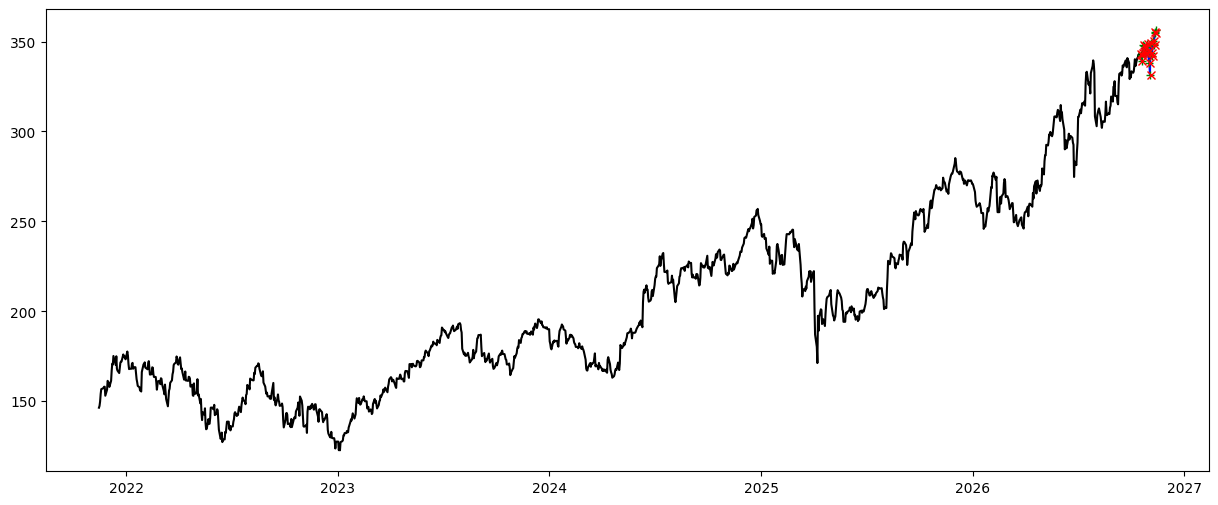

In [ ]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')   # Datos de entrenamiento (los históricos).
ax = plt.plot(test['y'], '-b')    # Datos de prueba reales (los últimos 20 registros a predecir).
ax = plt.plot(test['y'],'+g')
ax = plt.plot(test.index, predictions, 'xr')  # Predicciones del modelo ingenuo.

#Verdes son los datos reales
#rojos son las predicciones

### <font color=orange>**Interpretación Gráfica.**

----------------------------------------------------------------------------
En la gráfica se comparan los datos históricos de entrenamiento, los valores reales del conjunto de prueba y las predicciones realizadas por el modelo ingenuo. Se puede observar que las predicciones se mantienen cercanas a los valores reales, aunque presentan algunas diferencias cuando el precio cambia de manera más pronunciada. Esto se debe a que el modelo utiliza el último valor observado para estimar el siguiente, por lo que tiene dificultades para anticipar movimientos importantes. En general, el modelo logra seguir el comportamiento de la serie durante períodos con variaciones pequeñas.

----------------------------------------------------------------------------

# **2 - Modelo ARIMA**

# **DATOS ORIGINALES**

### **Análisis preliminar para obtener información de la serie de tiempo y construir el modelo ARIMA(p,d,q).**

*   **AR (AutoRegresivo):** El modelo se basa en la **relación entre un valor actual y sus valores pasados.**

*   **I (Integrado):** Se refiere a la diferenciación de la serie para hacerla estacionaria, es decir, eliminar tendencias y patrones cíclicos.

*   **MA (Media Móvil):** Usa el error de los valores pasados (las desviaciones entre valores predichos y observados) para corregir el valor actual.

##### **Ahora veamos el gráfico de descomposición de la serie de tiempo en sus componentes de tendencia (trend), estacionalidad (stationality) y residual (residual).**

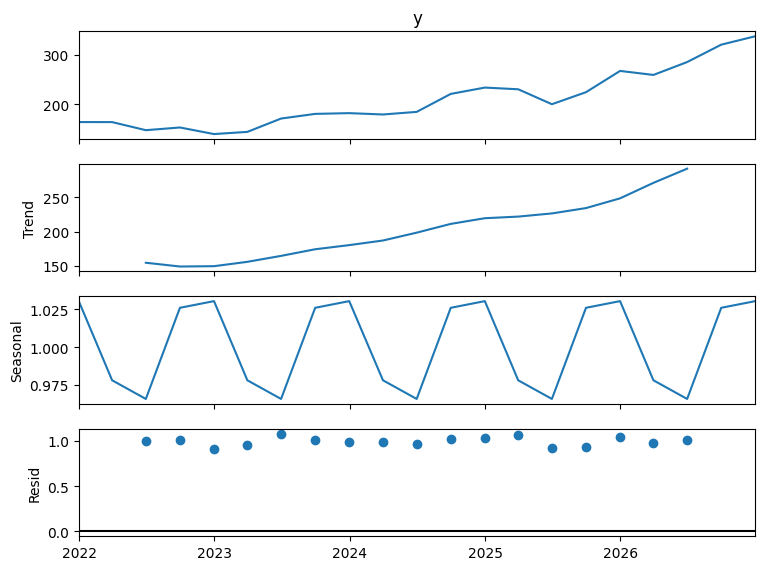

In [ ]:
# Gráficos de descomposición estacional:
#parametro Q indica año
decomposition = seasonal_decompose(train['y'].resample('Q').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <font color=orange>**Interpretación de cada una de las Gráficas**

-----------------------------------------------------------------------------

La gráfica de descomposición permite analizar los diferentes componentes de la serie de tiempo de Apple:

1. **Gráfica Original:** Muestra el comportamiento del precio de cierre de AAPL, donde se identifican variaciones y una tendencia general creciente durante el período analizado.
2. **Tendencia (Trend):** Se observa un crecimiento progresivo del precio a lo largo del tiempo, aunque existen algunos períodos de disminución. Esto indica que la serie presenta una tendencia positiva.
3. **Estacional (Seasonal):** El componente estacional presenta un patrón que se repite de manera periódica. Los valores se mantienen cercanos a 1, lo que indica que las variaciones estacionales son relativamente pequeñas en comparación con la tendencia.
4. **Residuos (Resid):** Los residuos representan las variaciones que no son explicadas por la tendencia ni por la estacionalidad. En la gráfica, los valores se encuentran relativamente cercanos a 1, lo que indica que las diferencias restantes son moderadas.

En general, la descomposición permite identificar una tendencia creciente y un comportamiento estacional que puede ser considerado durante la construcción del modelo ARIMA.
-----------------------------------------------------------------------------

##### **Veamos ahora estos dos gráficos que nos hablan si tenemos algún tipo de estacionalidad (i.e., periodicidad). En particular, mensual o trimestral:**

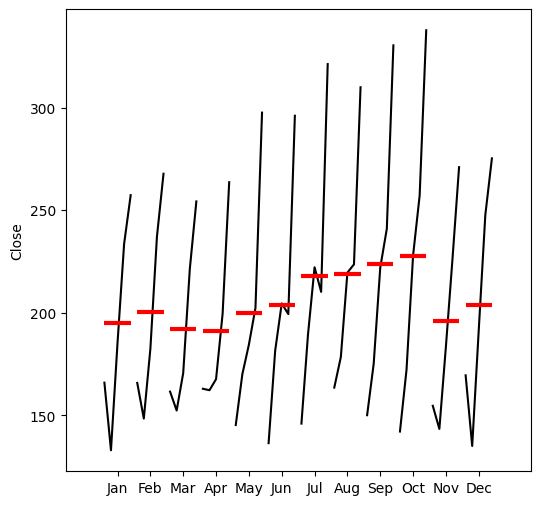

In [ ]:
# Gráfica para detección de estacionalidad mensual:
fig = month_plot(train['y'].resample('M').mean(), ylabel='Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------

En la gráfica se muestran los precios de cierre de Apple agrupados por mes, lo que permite observar posibles diferencias en su comportamiento a lo largo del año. Se identifican variaciones entre los meses, ya que algunos presentan promedios de cierre mayores que otros. Los valores promedio más elevados se observan aproximadamente en septiembre y octubre, mientras que marzo y abril presentan valores más bajos.

----------------------------------------------------------------------------

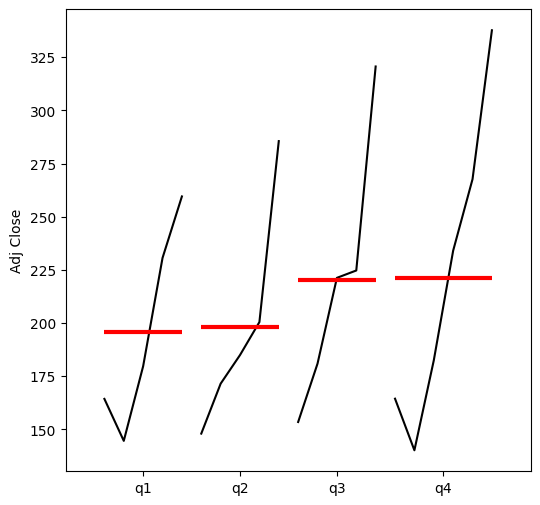

In [ ]:
# Si queremos graficar y detectar estacionalidad trimestral:
fig = quarter_plot(train['y'].resample('Q').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

----------------------------------------------------------------------------

La gráfica permite comparar el comportamiento del precio de cierre de Apple durante los cuatro trimestres del año. Se observa que el tercer y cuarto trimestre presentan promedios de cierre más elevados, cercanos a los 220 dólares, mientras que el primer y segundo trimestre muestran valores promedio menores. También se identifican aumentos y disminuciones dentro de cada trimestre.


----------------------------------------------------------------------------

### **Gráficos de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)**

*   Los gráficos de Autocorrelación miden la correlación entre la serie de tiempo y una versión rezagada de sí misma.

*   Este tipo de correlaciones de una serie de tiempo consigo misma son llamadas "autocorrelaciones" o "correlaciones seriales".

*   En el eje horizontal se muestra el valor del desfazamiento (lag) y en el eje vertical el valor de correlación de la serie desfazada y la original.

*   El cono sombreado indica intervalos de confianza de la correlación, con un 95% de confianza de manera predeterminada.

*   Que existan autocorrelaciones significativas en estos gráficos nos habla de que la serie de tiempo no es aleatoria.

*   En estos dos gráficos (llamados en inglés "pollipop plots") hay que determinar cuántos de estos lollipops están afuera del intervalo de confianza (sin contar el inicial) antes de que entre el siguiente a la zona celeste?

*   **Gráfico ACF:** Muestra la correlación total entre la serie y sus retardos, incluyendo efectos directos e indirectos.

*   **Gráfico PACF:** Muestra la correlación directa entre la serie y sus retardos, eliminando los efectos de los retardos intermedios.

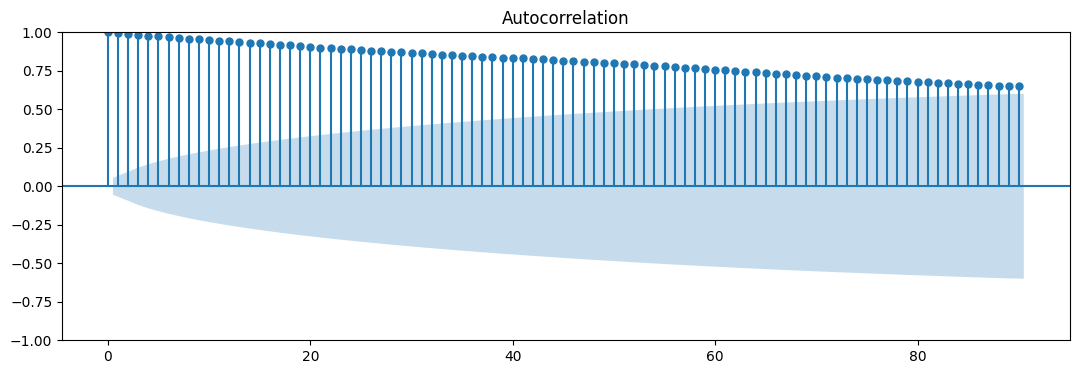

In [ ]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function)
train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN
fig,ax = plt.subplots(figsize = (13,4))
plot_acf(train['y'], lags=90, ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()

# <font color=orange>**Intepretación Gráfica Autocorrelación (ACF)**

-----------------------------------------------------------------------------

En la gráfica ACF se observa que las autocorrelaciones presentan valores positivos elevados y disminuyen de manera gradual conforme aumenta el número de desfases (lags). Además, varios valores se encuentran fuera del intervalo de confianza, lo que indica que existe una relación entre los valores actuales y los anteriores de la serie. Este comportamiento sugiere que el precio de cierre de Apple presenta dependencia temporal y que la serie original no es completamente aleatoria.


-----------------------------------------------------------------------------

El gráfico inicia con desfase (lag) de 0, lo cual es la correlación de la serie de tiempo consigo misma, la cual es 1.

Posteriormente se muestran las correlaciones de la serie de tiempo original, con la serie desfasada "q" lugares hacia atrás, es decir, de orden "q" en la componente MA de ARIMA(p,d,q).

**El gráfico ACF nos dice en primera instancia que la componente MA de ARIMA(p,d,q) tiene un grado "q" de 13 (en la práctica se puede buscar de 0 a 13).**

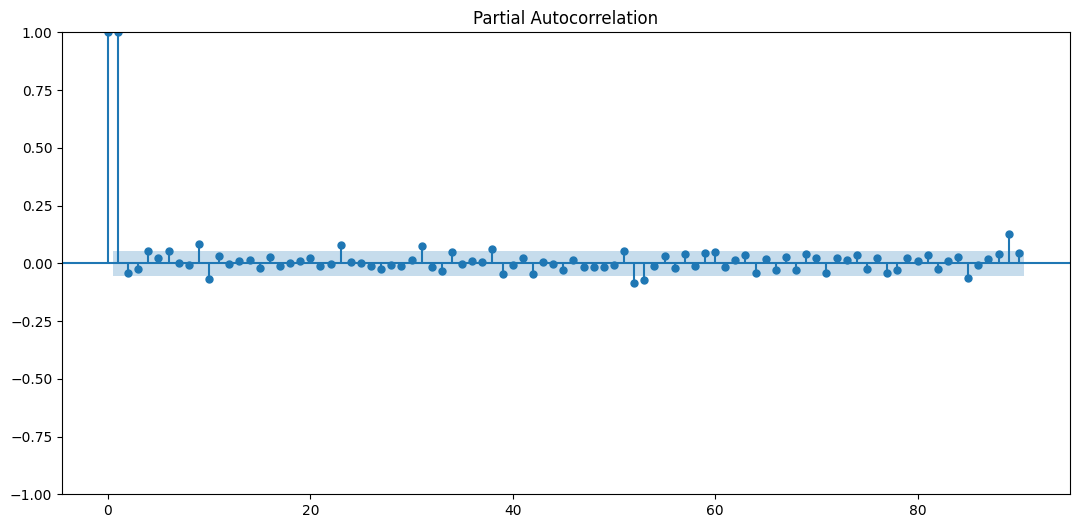

In [ ]:
# Gráfico de Autocorrelación Parcial (PACF):
fig, ax = plt.subplots(figsize = (13,6))
plot_pacf(train['y'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

# <font color=orange>**Interpretación Gráfica Partial Autoccorelation (PACF)**

----------------------------------------------------------------------------
En la gráfica PACF se observa que la mayoría de los valores de autocorrelación parcial se encuentran dentro del intervalo de confianza, aunque existen algunos desfases que presentan valores significativos. Esto permite identificar las relaciones directas entre la serie y sus valores anteriores, sin considerar el efecto de los desfases intermedios.

----------------------------------------------------------------------------

* PACF también inicia con la correlación de la serie de tiempo consigo misma, por ello el valor de 1.

*   **De este gráfico podemos observar que la componente AR de ARIMA(p,d,q) tiene grado p=3 o tal vez 5 (en la práctica se puede probar de 0 a 5.)**

##### Existe un buen número de librerías para el caso de pronósticos con los modelos ARIMA-SARIMA. Usaremos en este ejercicio la de Statsmodels, cuya documentación encuentras en la siguiente liga:

https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
# Lo primero es para quitar la estacionalidad y transformar un problema
# de tipo no-estacionario (SARIMA) en uno estacionario (ARIMA):

# Diferencia de datos consecutivos en el tiempo
# y podemos ahora usar ARIMA:
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)



# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]


In [ ]:
# Definamos la siguiente lista de registros de pasajeros en el tiempo:
history = [x for x in train.loc[:,'y'].values]   # train-ndarray : columna solo con los registros de pasajeros "y".
                               # history-list : lista con los datos del train.

predictions = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test['y'])):
  #
  months_in_year = 12
  diff = difference(history, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.    (p,d,q)  p->valor definido en gráfica partial autocorrelation  d->Estacionaria  q->valor definido en grafica autocorrelacion
  model = ARIMA(diff, order=(1,0,13),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit = model.fit(method_kwargs={'maxiter':300})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat = model_fit.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat = inverse_difference(history, yhat, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions.append(yhat)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs = test.iloc[i]['y']   #  cada dato es un flotante.
  history.append(obs)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 342, Predicción = 342.468
>Esperado-real = 339, Predicción = 343.080
>Esperado-real = 343, Predicción = 338.825
>Esperado-real = 347, Predicción = 342.091
>Esperado-real = 347, Predicción = 349.595
>Esperado-real = 343, Predicción = 346.090


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


>Esperado-real = 346, Predicción = 343.664


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


>Esperado-real = 343, Predicción = 347.818
>Esperado-real = 348, Predicción = 343.360
>Esperado-real = 344, Predicción = 349.778
>Esperado-real = 338, Predicción = 343.110
>Esperado-real = 331, Predicción = 338.122
>Esperado-real = 349, Predicción = 330.463
>Esperado-real = 343, Predicción = 350.829
>Esperado-real = 342, Predicción = 343.320
>Esperado-real = 350, Predicción = 341.567
>Esperado-real = 348, Predicción = 351.122
>Esperado-real = 355, Predicción = 347.778
>Esperado-real = 354, Predicción = 355.166
>Esperado-real = 356, Predicción = 354.770

Error-Modelo-ARIMA: RMSE: 6.265


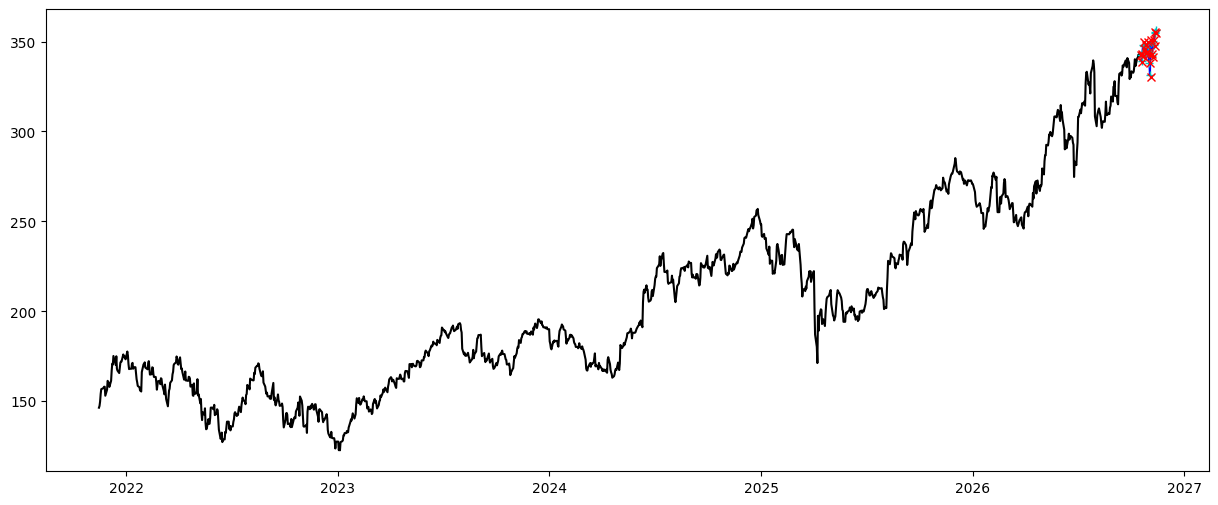

In [ ]:
# Veamos su gráfico de ARIMA:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')
ax = plt.plot(test['y'], '-b')
ax = plt.plot(test['y'], '+c')
ax = plt.plot(test.index, predictions, 'xr')

# <font color=orange>**Interpretación Gráfica ARIMA**

-----------------------------------------------------------------------------
En la gráfica se comparan los valores históricos de entrenamiento, los precios reales del conjunto de prueba y las predicciones realizadas por el modelo ARIMA. Se observa que las predicciones se mantienen cercanas a los valores reales de las acciones de Apple, logrando representar de manera adecuada el comportamiento de la serie durante el período evaluado. Aunque existen algunas diferencias entre los valores esperados y los estimados, el modelo consigue seguir las variaciones del precio de cierre.

El modelo ARIMA obtuvo un RMSE de 6.265, lo que indica un error relativamente bajo en sus predicciones. Esto demuestra que, con los nuevos valores de los parámetros, ARIMA logró mejorar su capacidad de pronóstico, aunque el modelo Naive continúa presentando un error menor.

----------------------------------------------------------------------------



# **3 - Modelo Facebook-Meta-Prophet**

# **DATOS ORIGINALES**

#### **En la liga del modelo Facebook-Prophet puedes encontrar mucho más información, además de la documentación correspondiente:**

https://facebook.github.io/prophet/

In [ ]:
df_temp.head() #verificar que el df_temp este en formato correcto

,y
Date,
2021-11-15,146.407959
2021-11-16,147.384003
2021-11-17,149.814392
2021-11-18,154.089478
2021-11-19,156.705292


In [ ]:
# Prophet requiere que la entrada sean dos columnas, llamadas "ds" y "y".
# Les dmos esta forma usando el DataFrame "df" inicial:
df_temp = df_temp.reset_index() #reseta el indice
df_temp = df_temp.rename(columns={'Date': 'ds'}) #renombra columna 'Date' como 'ds'
df_temp.head()


,ds,y
0,2021-11-15,146.407959
1,2021-11-16,147.384003
2,2021-11-17,149.814392
3,2021-11-18,154.089478
4,2021-11-19,156.705292


In [ ]:
train =df_temp.iloc[0:-20,:] #particion Entrenamiento, todo el conjunto excepto últimos 20
test = df_temp.iloc[-20:,:]  #particion Prueba, solo ultimos 20 registros de df_temp

In [ ]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model = Prophet(seasonality_mode='multiplicative', #se especifica el modo multiplicativo que se definio en los modelos anteriores
                yearly_seasonality=True,       #periodo anual Verdadero
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Calculamos el error RMSE:

pred_FP = model.predict(test)['yhat']
rmse = np.sqrt(mean_squared_error(test['y'], pred_FP))
print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet: RMSE: 9.139


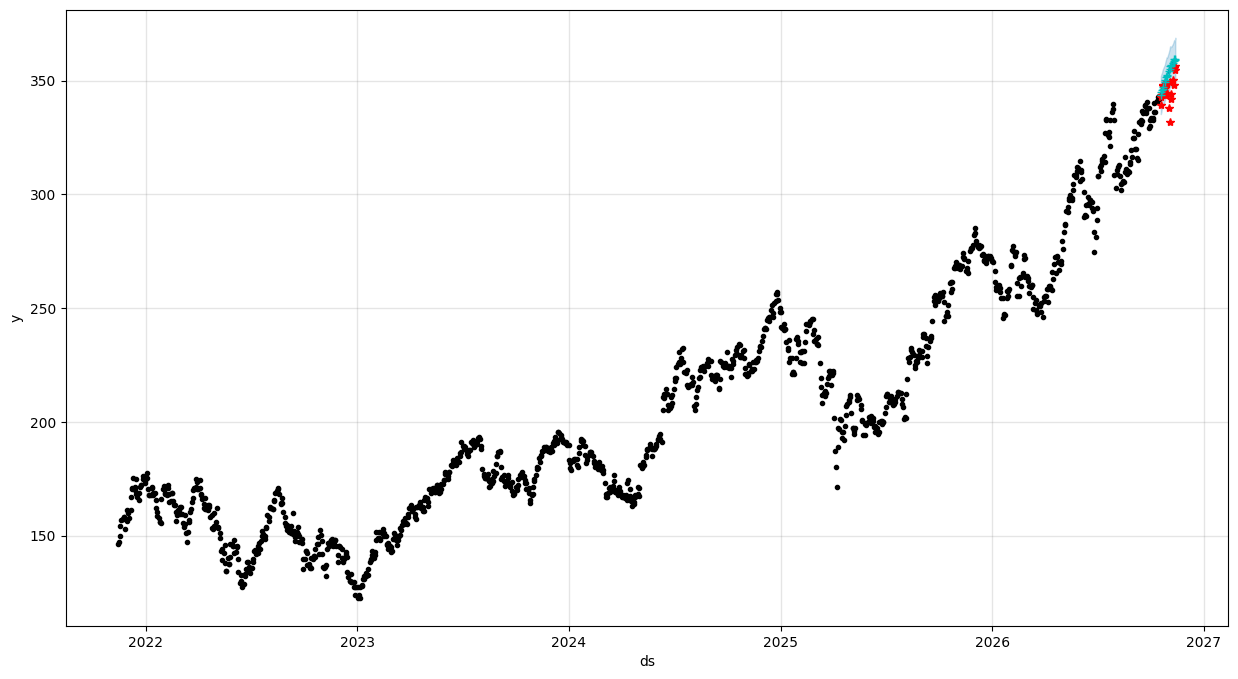

In [ ]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast = model.predict(test)

fig, ax = plt.subplots(figsize=(15, 8))
model.plot(forecast, ax=ax)               # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test['ds'], test['y'], '*r')   # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test['ds'], forecast['yhat'], '+c')    # Valores reales.

#color rojo representan las predicciones
#color azul datos reales


# <font color=orange>**Interpretación Gráfica Facebook-Meta-Prophet**

-----------------------------------------------------------------------------
En la gráfica se puede observar la predicción del modelo Prophet (línea continua), acompañada de una banda sombreada que representa el nivel de incertidumbre. También se muestran los valores reales del conjunto de prueba (puntos rojos) y las predicciones del modelo (cruces color cian). La banda de confianza es bastante amplia, lo que indica que existe cierta incertidumbre en las estimaciones. Aunque los valores reales se mantienen dentro o cerca de esta banda, hacia el final de la serie la línea de predicción queda por debajo de los valores reales, debido al aumento más pronunciado del precio.

El RMSE obtenido fue de 9.139, el más alto entre los cuatro modelos evaluados con los datos originales. Esto indica que Prophet tuvo mayores errores en sus predicciones y que, con los valores de configuración utilizados (changepoint_prior_scale=10 y seasonality_prior_scale=30), no consiguió representar adecuadamente el crecimiento del precio de las acciones de AAPL.

-----------------------------------------------------------------------------


# **4 - Long Short Term Memory (LSTM)**

# **DATOS ORIGINALES**

In [ ]:
import tensorflow as tf

In [ ]:
test.head()

,ds,y
1285,2026-10-19,342.679626
1286,2026-10-20,339.242249
1287,2026-10-21,343.728821
1288,2026-10-22,347.955627
1289,2026-10-23,347.466003


In [ ]:
def preparando_datos(myData, myDate):

  # ++++++++ TRAIN +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de entrenamiento son previos a la fecha "Date" que indiques y
  # tomarán hisotriales en este caso de 12 períodos previos.
  Train_Data = myData['y'][myData['ds'] < myDate].to_numpy()

  periodo = 12   # 12 meses al año

  Data_Train = []
  Data_Train_X = []
  Data_Train_Y = []

  for i in range(0, len(Train_Data), periodo):    # observa que va formando el Train set con historiales de 12 períodos consecutivos.
    try:
      Data_Train.append(Train_Data[i : i + periodo])
    except:
      pass


  # En ocasiones hay datos perdidos, en cuyo caso la última serie
  # de datos la eliminamos:
  if len(Data_Train[-1]) < periodo:
    Data_Train.pop(-1)


  # Hay que darle la forma (dimensionalidad) que requieren los modelos
  # de aprendizaje profundo, en particular la librería de TensorFlow:
  #     (batch_size, sequence_length, input_dimension).

  Data_Train_X = Data_Train[0 : -1]
  Data_Train_X = np.array(Data_Train_X)
  Data_Train_X = Data_Train_X.reshape((-1, periodo, 1))

  Data_Train_Y = Data_Train[1 : len(Data_Train)]
  Data_Train_Y = np.array(Data_Train_Y)
  Data_Train_Y = Data_Train_Y.reshape((-1, periodo, 1))


  # +++++++++++ TEST +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de prueba (Test) son posteriores a la fecha "Date" y que es el
  # último ciclo que deseas predecir:
  Test_Data = myData['y'][myData['ds'] >= myDate].to_numpy()

  # inicialización de listas:
  Data_Test = []
  Data_Test_X = []
  Data_Test_Y = []

  for i in range(0, len(Test_Data), periodo):
    try:
      Data_Test.append(Test_Data[i : i + periodo])
    except:
      pass


  if len(Data_Test[-1]) < periodo:
    Data_Test.pop(-1)

  Data_Test_X = Data_Test[0 : -1]
  Data_Test_X = np.array(Data_Test_X)
  Data_Test_X = Data_Test_X.reshape((-1, periodo, 1))

  Data_Test_Y = Data_Test[1 : len(Data_Test)]
  Data_Test_Y = np.array(Data_Test_Y)
  Data_Test_Y = Data_Test_Y.reshape((-1, periodo, 1))


  return Data_Train_X, Data_Train_Y, Data_Test_X, Data_Test_Y


In [ ]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date = '2026-09-11'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp, threshold_Date)#aplica df temporal

In [ ]:
# Podemos definir la manera en que el tamaño de paso (learning-rate) varíe
# en cada época. Es usual definir también algunas funciones, exponenciales,
# por ejemplo. Por el momento definamos valores constantes por intervalos:

def scheduler(epoch):

  if epoch <= 50: #100
    lrate = 0.001 #0.05
  elif epoch <= 100:
    lrate = 0.0005
  elif epoch <=150:
    lrate = 0.00001
  else:
    lrate = 0.00005

  return lrate


callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - loss: 43017.5664 - root_mean_squared_error: 207.4068 - val_loss: 111059.7812 - val_root_mean_squared_error: 333.2563 - learning_rate: 0.0010
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 42897.5430 - root_mean_squared_error: 207.1172 - val_loss: 111365.0547 - val_root_mean_squared_error: 333.7140 - learning_rate: 0.0010
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 42785.0469 - root_mean_squared_error: 206.8455 - val_loss: 111173.0703 - val_root_mean_squared_error: 333.4263 - learning_rate: 0.0010
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 42663.3320 - root_mean_squared_error: 206.5510 - val_loss: 110444.0547 - val_root_mean_squared_error: 332.3312 - learning_rate: 0.0010
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 42537.4922 - root_mean_squared_error: 206.2462 - val_loss: 110374.1953 - val_root_mean_squared_error: 332.2261 - learning_rate: 0.0010
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━

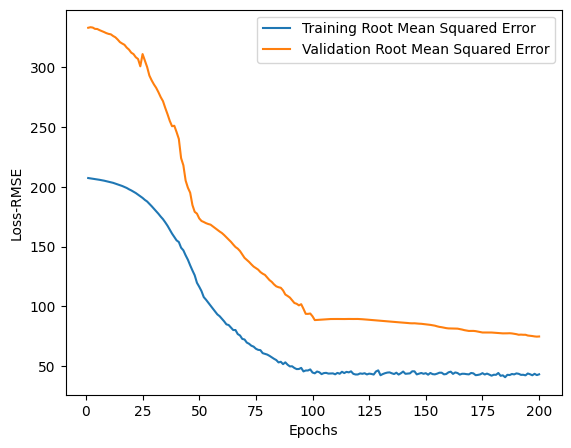

In [ ]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(20, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      #tf.keras.layers.Dense(12, activation='linear')
                                      tf.keras.layers.Dense(1, activation='linear')
                                      ])
  return model


# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 0  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [ ]:
pred_LSTM=my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


(24,)

In [ ]:
# Calculamos el error RMSE:

pred_LSTM = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM = pred_LSTM.reshape(-1)[-20:]  # Elegir los últimos 20 valores
rmse = np.sqrt(mean_squared_error(test['y'].values, pred_LSTM))

print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step

Error-Modelo-FacebookProphet: RMSE: 61.220


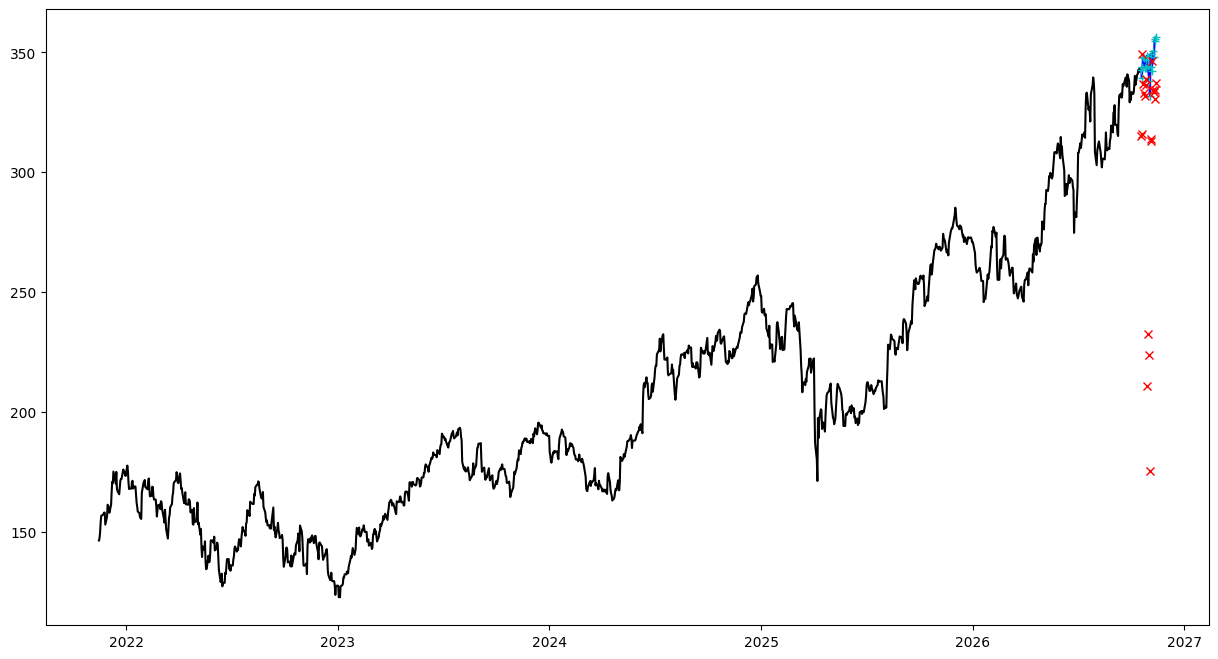

In [ ]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 8))
ax = plt.plot(train['ds'], train['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test['ds'], test['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], test['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], pred_LSTM, 'xr')  # Predicciones del modelo del año 1960.

**Habría que buscar la mejor arquitectura y ejecutarlo varias veces para obtener un mejor resultado.**

# <font color=orange>**Interpretación Gráfica Long Short Term Memory (LSTM)**

----------------------------------------------------------------------------
En la gráfica se comparan los datos utilizados para el entrenamiento (línea negra), los valores reales del conjunto de prueba (línea azul con cruces cian) y las predicciones realizadas por el modelo LSTM (cruces rojas). Se puede observar que las predicciones se encuentran bastante alejadas de los valores reales, ya que el modelo estima precios entre 270 y 290, mientras que los valores reales se mantienen aproximadamente entre 330 y 356. Esto muestra que el modelo tiene dificultades para seguir la tendencia creciente de la serie y realizar estimaciones cercanas a los precios reales.

El RMSE obtenido fue de 61.220, un valor considerablemente más alto que el de los demás modelos.

----------------------------------------------------------------------------

# <font color=orange>**Interpretación Valores RMSE Obtenidos de los modelos Ingenuo, ARIMA, Prophet y LSTM aplicado con Datos Orginales**</font>

-----------------------------------------------------------------------------

Los resultados obtenidos de RMSE, fueron los siguientes:

| # | Modelo  | Datos Originales RMSE |
|---|---------|-----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) |5.825 |
| 2 | Modelo ARIMA |  6.265|
| 3 | Modelo Facebook-Meta-Prophet |9.139|
| 4 | Long Short Term Memory (LSTM) |61.220 |

**<font color=orange>INTERPRETACIÓN Y CONCLUSIÓN DE LA PRÁCTICA: </FONT>**

Los resultados muestran que el modelo ingenuo obtuvo el mejor desempeño (RMSE = 5.825), seguido de ARIMA (6.265), cuyos resultados fueron bastante cercanos. Por otro lado, Prophet presentó un error mayor (9.139), lo que indica que tuvo dificultades para representar la tendencia creciente de los precios de AAPL. El modelo LSTM fue el que obtuvo el peor resultado (61.220), debido a que no logró seguir el comportamiento de la serie y generó predicciones muy alejadas de los valores reales. En general, se observa que utilizar modelos más complejos no garantiza mejores resultados, ya que, en este caso, el modelo ingenuo fue el más preciso. Esto demuestra la importancia de comparar cada modelo con una referencia sencilla y ajustar sus parámetros antes de considerar que puede ofrecer mejores predicciones.
---------------------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **A continuación, se aplicaran los mismos modelos planteados anteriormente (Ingenuo, ARIMA, Prophet y LSTM), pero aplicando escalamiento MinMaxScaler al conjunto de datos que estamos trabajando (ADJ-CLOSE).**

# **0 -PREPARACIÓN DATOS PARA ESCALAMIENTO**

# **DATOS ESCALADOS**

In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))#aplica escalamiento rango 0,1

#Aplica Escalamiento a Entrenamiento y Prueba
train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
test.loc[:, 'y_escalado']=scaler.transform(test[['y']])

In [ ]:
train.head() #para visualizar nueva columna con los valores 'y' escalados

,ds,y,y_escalado
0,2021-11-15,146.407959,0.107380
1,2021-11-16,147.384003,0.111808
2,2021-11-17,149.814392,0.122832
3,2021-11-18,154.089478,0.142223
4,2021-11-19,156.705292,0.154088


In [ ]:
#Elimina columna 'y' para quedarnos solo con las columnas: 'ds'  'y_escalado'
train_escalado=train.drop(columns=['y'])
test_escalado=test.drop(columns=['y'])

In [ ]:
train_escalado.head()#verifica eliminacion columna 'y'

,ds,y_escalado
0,2021-11-15,0.107380
1,2021-11-16,0.111808
2,2021-11-17,0.122832
3,2021-11-18,0.142223
4,2021-11-19,0.154088


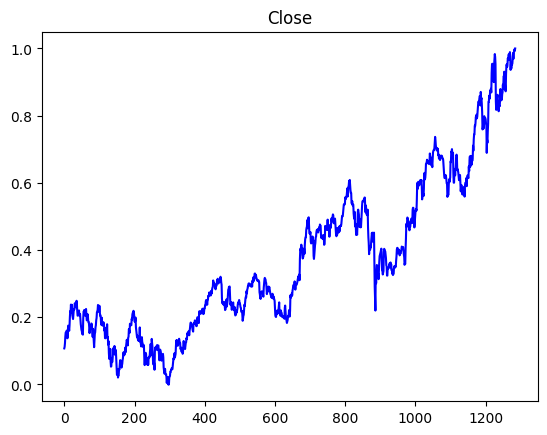

In [ ]:
train_escalado['y_escalado'].plot(title='Close', style='-b')
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo Obtenido en Datos Originales**

-----------------------------------------------------------------------------
La gráfica muestra la serie de precios de cierre de AAPL después de aplicar el escalamiento MinMaxScaler al rango [0,1]. Se aprecia la misma forma que la serie original, pero los valores ahora están acotados entre 0 y 1. Este escalamiento facilita el entrenamiento de modelos sensibles a la magnitud de los datos, como las redes neuronales, y permite comparar directamente el error (RMSE) en la misma escala.

-----------------------------------------------------------------------------

In [ ]:
test_escalado['y_escalado'].values   #muestra valores del test con los datos escalados

array([0.9976432 , 0.9820517 , 1.00240221, 1.02157445, 1.01935358,
       1.00203967, 1.01649818, 1.001677  , 1.02470186, 1.00530301,
       0.97670342, 0.94760522, 1.02742133, 1.00321808, 0.99505966,
       1.03276948, 1.02288879, 1.05515966, 1.05298253, 1.05928732])

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ESCALADOS**

In [ ]:
history = [x for x in train_escalado['y_escalado'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test_escalado['y_escalado'])):
  # Obtenemos las predicciones:
  yhat_scaled = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat_scaled)

  # Observaciones-registros reales:
  obs_scaled = test_escalado.iloc[i]['y_escalado']   # Ahora vamos tomando los datos de Test.
  history.append(obs_scaled)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_scaled, yhat_scaled))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test_escalado['y_escalado'].values, predictions))
print('\nError-Modelo-Naive con datos escalados: RMSE: %.3f' % rmse)

>Esperado-real = 0.998, Predicción = 1.000
>Esperado-real = 0.982, Predicción = 0.998
>Esperado-real = 1.002, Predicción = 0.982
>Esperado-real = 1.022, Predicción = 1.002
>Esperado-real = 1.019, Predicción = 1.022
>Esperado-real = 1.002, Predicción = 1.019
>Esperado-real = 1.016, Predicción = 1.002
>Esperado-real = 1.002, Predicción = 1.016
>Esperado-real = 1.025, Predicción = 1.002
>Esperado-real = 1.005, Predicción = 1.025
>Esperado-real = 0.977, Predicción = 1.005
>Esperado-real = 0.948, Predicción = 0.977
>Esperado-real = 1.027, Predicción = 0.948
>Esperado-real = 1.003, Predicción = 1.027
>Esperado-real = 0.995, Predicción = 1.003
>Esperado-real = 1.033, Predicción = 0.995
>Esperado-real = 1.023, Predicción = 1.033
>Esperado-real = 1.055, Predicción = 1.023
>Esperado-real = 1.053, Predicción = 1.055
>Esperado-real = 1.059, Predicción = 1.053

Error-Modelo-Naive con datos escalados: RMSE: 0.026


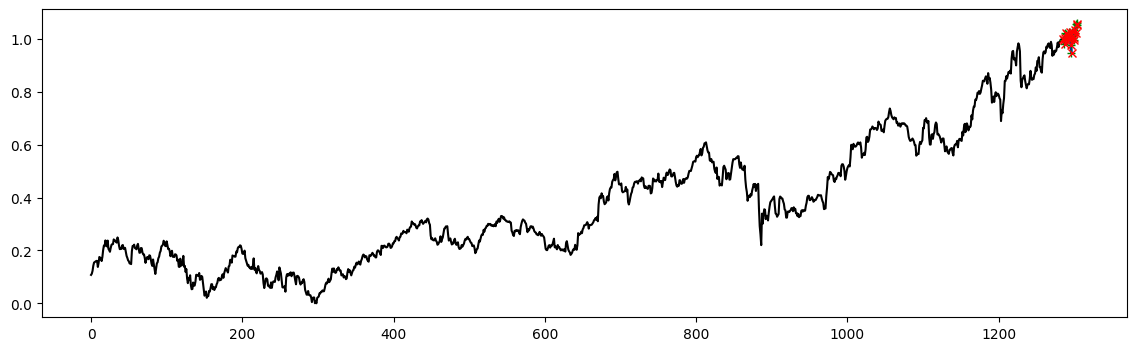

In [ ]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(14, 4))
ax = plt.plot(train_escalado['y_escalado'], '-k')  # Datos de entrenamiento (los históricos).
ax = plt.plot(test_escalado['y_escalado'], '-b')    # Datos de prueba reales (los del útimo año a predecir).
ax = plt.plot(test_escalado['y_escalado'],'+g')
ax = plt.plot(test_escalado.index, predictions, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en el modelo ingenuo con los datos originales**

----------------------------------------------------------------------------
En la gráfica se muestran los datos de entrenamiento escalados (línea negra), los valores reales de prueba (línea azul) y las predicciones del modelo ingenuo (cruces rojas). Se observa que las predicciones siguen un paso detrás de los valores reales, ya que el modelo simplemente repite el último dato registrado. El RMSE fue de 0.026, equivalente aproximadamente al mismo error que se obtuvo con los datos originales (5.825). Esto demuestra que el escalamiento no mejora las predicciones del modelo, sino que únicamente cambia la escala de los valores.

----------------------------------------------------------------------------

# **2 - Modelo ARIMA**
# **DATOS ESCALADOS**

In [ ]:
#copia df con Conjunto Entrenamiento
train_escalado2=train_escalado.copy()
train_escalado2.head()

,ds,y_escalado
0,2021-11-15,0.107380
1,2021-11-16,0.111808
2,2021-11-17,0.122832
3,2021-11-18,0.142223
4,2021-11-19,0.154088


In [ ]:
#copia df Conjunto de Prueba
test_escalado2=test_escalado.copy()
test_escalado2.head()

,ds,y_escalado
1285,2026-10-19,0.997643
1286,2026-10-20,0.982052
1287,2026-10-21,1.002402
1288,2026-10-22,1.021574
1289,2026-10-23,1.019354


In [ ]:
train_escalado2 = train_escalado2.set_index('ds') #Aplica ds como índice en conjunto entrenamiento

In [ ]:
test_escalado2 =test_escalado2.set_index('ds')   #Aplica ds como índice en conjunto de Prueba

In [ ]:
train_escalado2.head()  #Verifica datos escalados Entrenamiento

,y_escalado
ds,
2021-11-15,0.107380
2021-11-16,0.111808
2021-11-17,0.122832
2021-11-18,0.142223
2021-11-19,0.154088


In [ ]:
test_escalado2.head() #Verificar datos Escalados Prueba

,y_escalado
ds,
2026-10-19,0.997643
2026-10-20,0.982052
2026-10-21,1.002402
2026-10-22,1.021574
2026-10-23,1.019354


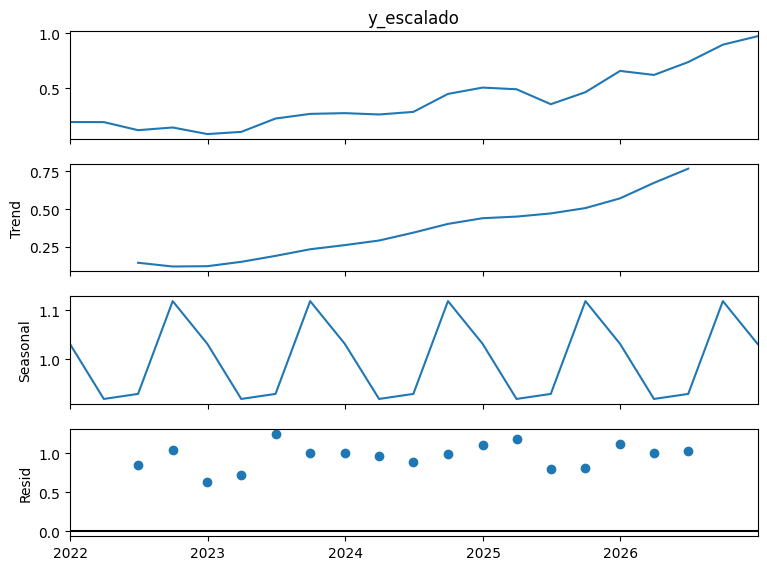

In [ ]:
# Gráficos de descomposición estacional con datos escalados:
decomposition = seasonal_decompose(train_escalado2['y_escalado'].resample('QE').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con Datos Originales**

------------------------------------------------------------------------
La descomposición de la serie escalada conserva los mismos componentes que los datos originales, pero ajustados al rango [0,1]. La tendencia continúa siendo creciente. La estacionalidad presenta variaciones pequeñas y los residuos no muestran un patrón definido. En general, el escalamiento no modifica el comportamiento de la serie, únicamente cambia la magnitud de sus valores, por lo que las conclusiones siguen siendo las mismas que con los datos originales.
--------------------------------------------------------------------------

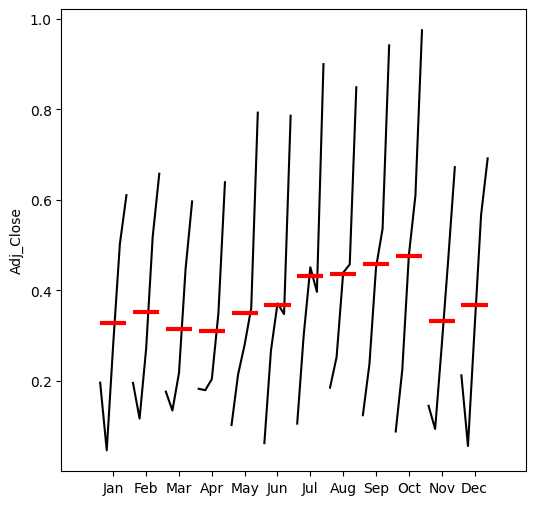

In [ ]:
# Gráfica para detección de estacionalidad mensual con datos escalados:
fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

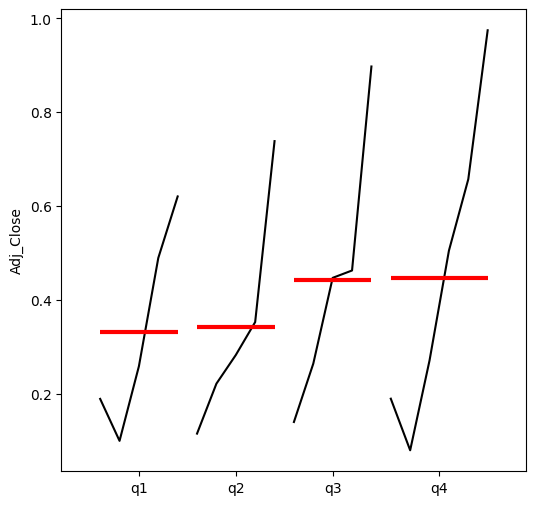

In [ ]:
# Si queremos graficar y detectar estacionalidad trimestral con datos escalados:
fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

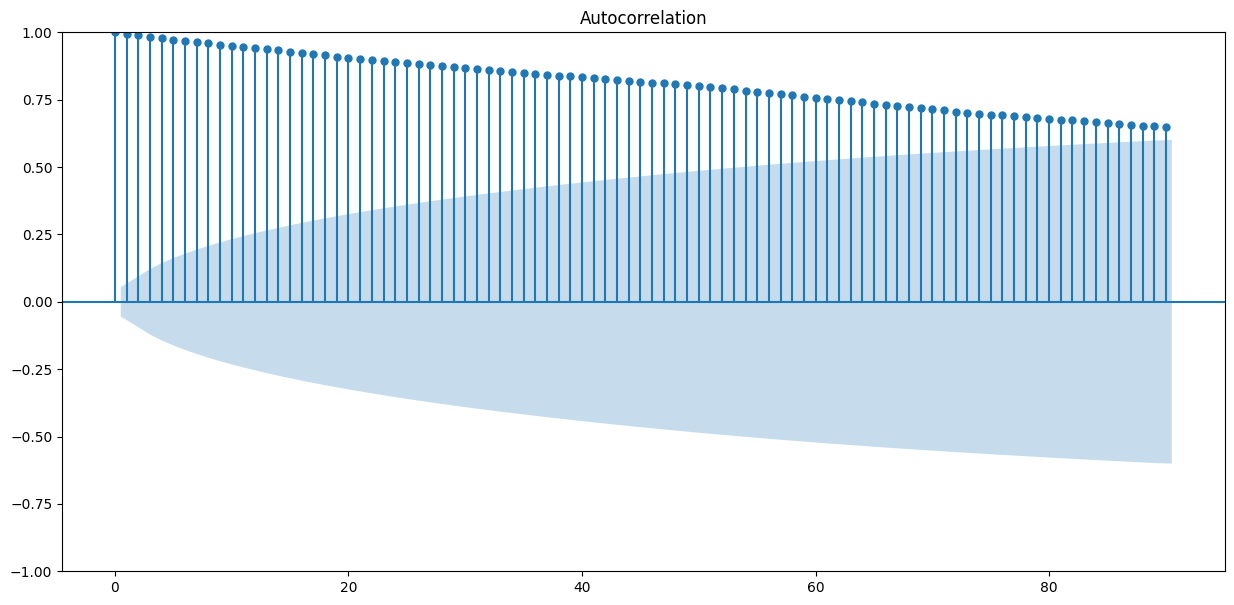

In [ ]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function) con datos escalados
fig,ax = plt.subplots(figsize = (15,7))
plot_acf(train_escalado2['y_escalado'], lags = 90,ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()                          # que define la partición en el eje horizontal. El área no sombreada nos habla de
                                    # la cantidad de períodos de tiempo hacia atrás cuya información proporcionada es
                                    # significativa para la predicción futura.


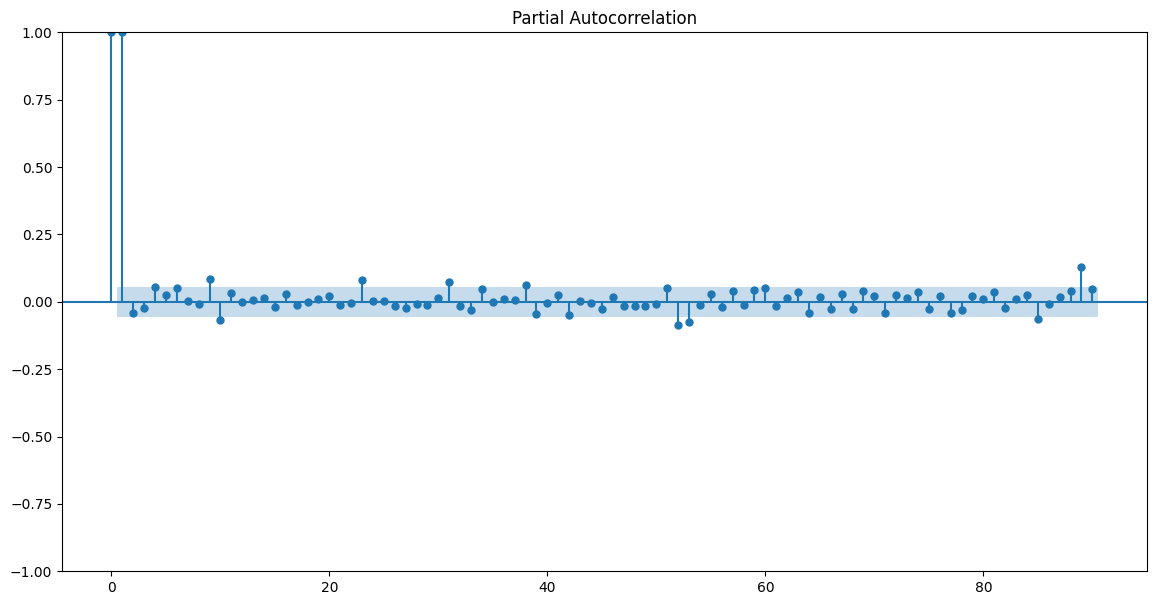

In [ ]:
# Gráfico de Autocorrelación Parcial (PACF) con datos escalados:
fig, ax = plt.subplots(figsize = (14,7))
plot_pacf(train_escalado2['y_escalado'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

In [ ]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo con datos escalados:
history_escalado = [x for x in train_escalado2.loc[:,'y_escalado'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions_escalado = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test_escalado2['y_escalado'])):
  #
  months_in_year = 12
  diff = difference(history_escalado, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.
  model_escalado = ARIMA(diff, order=(1,0,5),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit_escalado = model_escalado.fit(method_kwargs={'maxiter':500})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat_escalado = model_fit_escalado.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat_escalado = inverse_difference(history_escalado, yhat_escalado, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions_escalado.append(yhat_escalado)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs_escalado = test_escalado2.iloc[i]['y_escalado']   #  cada dato es un flotante.
  history_escalado.append(obs_escalado)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_escalado, yhat_escalado))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test_escalado2['y_escalado'].values, predictions_escalado))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 0.998, Predicción = 0.983
>Esperado-real = 0.982, Predicción = 1.008
>Esperado-real = 1.002, Predicción = 0.977
>Esperado-real = 1.022, Predicción = 0.999
>Esperado-real = 1.019, Predicción = 1.034
>Esperado-real = 1.002, Predicción = 1.029
>Esperado-real = 1.016, Predicción = 0.981
>Esperado-real = 1.002, Predicción = 1.033
>Esperado-real = 1.025, Predicción = 1.001
>Esperado-real = 1.005, Predicción = 1.026
>Esperado-real = 0.977, Predicción = 1.004
>Esperado-real = 0.948, Predicción = 0.978
>Esperado-real = 1.027, Predicción = 0.949
>Esperado-real = 1.003, Predicción = 1.013
>Esperado-real = 0.995, Predicción = 1.028
>Esperado-real = 1.033, Predicción = 1.009
>Esperado-real = 1.023, Predicción = 1.036
>Esperado-real = 1.055, Predicción = 1.005
>Esperado-real = 1.053, Predicción = 1.066
>Esperado-real = 1.059, Predicción = 1.040

Error-Modelo-ARIMA: RMSE: 0.031


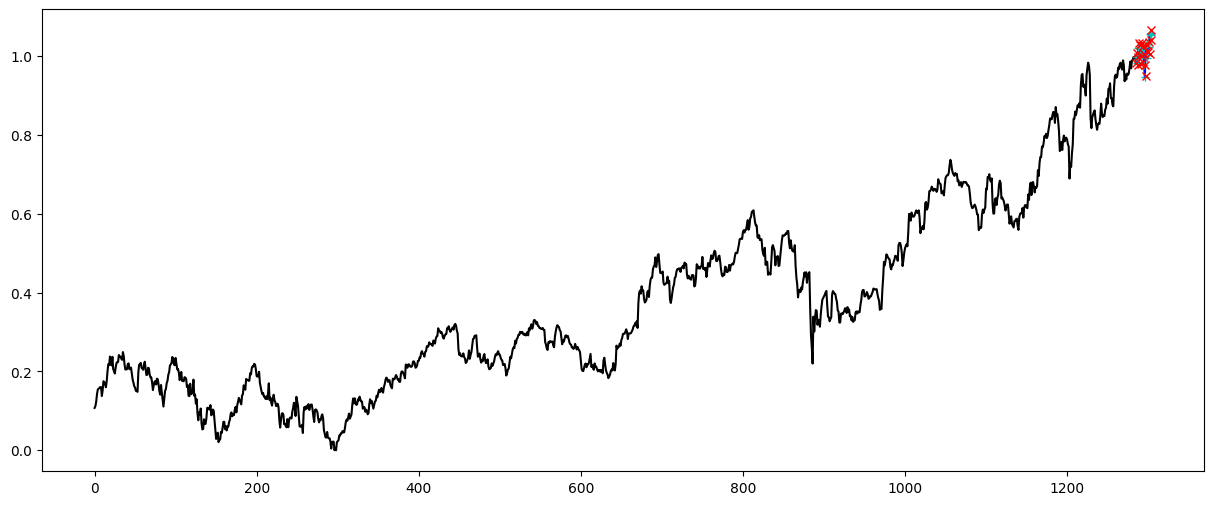

In [ ]:
# Veamos su gráfico:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train_escalado['y_escalado'], '-k')
ax = plt.plot(test_escalado['y_escalado'], '-b')
ax = plt.plot(test_escalado['y_escalado'], '+c')
ax = plt.plot(test_escalado.index, predictions_escalado, 'xr')

# <FONT COLOR=ORANGE>**Interpretación Gráfica Modelo ARIMA, Comparativa con datos originales**

------------------------------------------------------------------------
La gráfica muestra que las predicciones de ARIMA (cruces rojas) siguen de cerca el comportamiento de los datos reales, aunque presentan cierto retraso cuando la serie cambia de dirección. El RMSE obtenido fue de 0.031, ligeramente mayor que el del modelo ingenuo (0.026), por lo que ARIMA tampoco logró superar al modelo base.
-------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**
# **DATOS ESCALADOS**

In [ ]:
df_temp_escalado=df_temp.copy() #copia en nuevo df
df_temp_escalado.head()

,ds,y
0,2021-11-15,146.407959
1,2021-11-16,147.384003
2,2021-11-17,149.814392
3,2021-11-18,154.089478
4,2021-11-19,156.705292


In [ ]:
df_temp_escalado= df_temp_escalado.rename(columns={'Date':'ds','y_escalado':'y'})
df_temp_escalado.head()

,ds,y
0,2021-11-15,146.407959
1,2021-11-16,147.384003
2,2021-11-17,149.814392
3,2021-11-18,154.089478
4,2021-11-19,156.705292


In [ ]:
train_escalado = df_temp_escalado.iloc[0:-20,:] #partición Entrenamiento. Todos menos los últimos 20 registros
test_escalado = df_temp_escalado.iloc[-20:,:] #partición Prueba. Solo los últimos 20 registros

In [ ]:
#Aplica Escalamiento MinMaxScaler a entrenamiento y prueba
scaler = MinMaxScaler(feature_range=(0, 1))
train_escalado.loc[:, 'y']=scaler.fit_transform(train_escalado[['y']])
test_escalado.loc[:, 'y']=scaler.transform(test_escalado[['y']])

In [ ]:
train_escalado.head()

,ds,y
0,2021-11-15,0.107380
1,2021-11-16,0.111808
2,2021-11-17,0.122832
3,2021-11-18,0.142223
4,2021-11-19,0.154088


In [ ]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model_escalado = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30,)   # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model_escalado.fit(train_escalado)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Calculamos el error RMSE con datos escalados:
pred_FP_escalado = model_escalado.predict(test_escalado)['yhat']
rmse = np.sqrt(mean_squared_error(test_escalado['y'], pred_FP_escalado))
print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.034


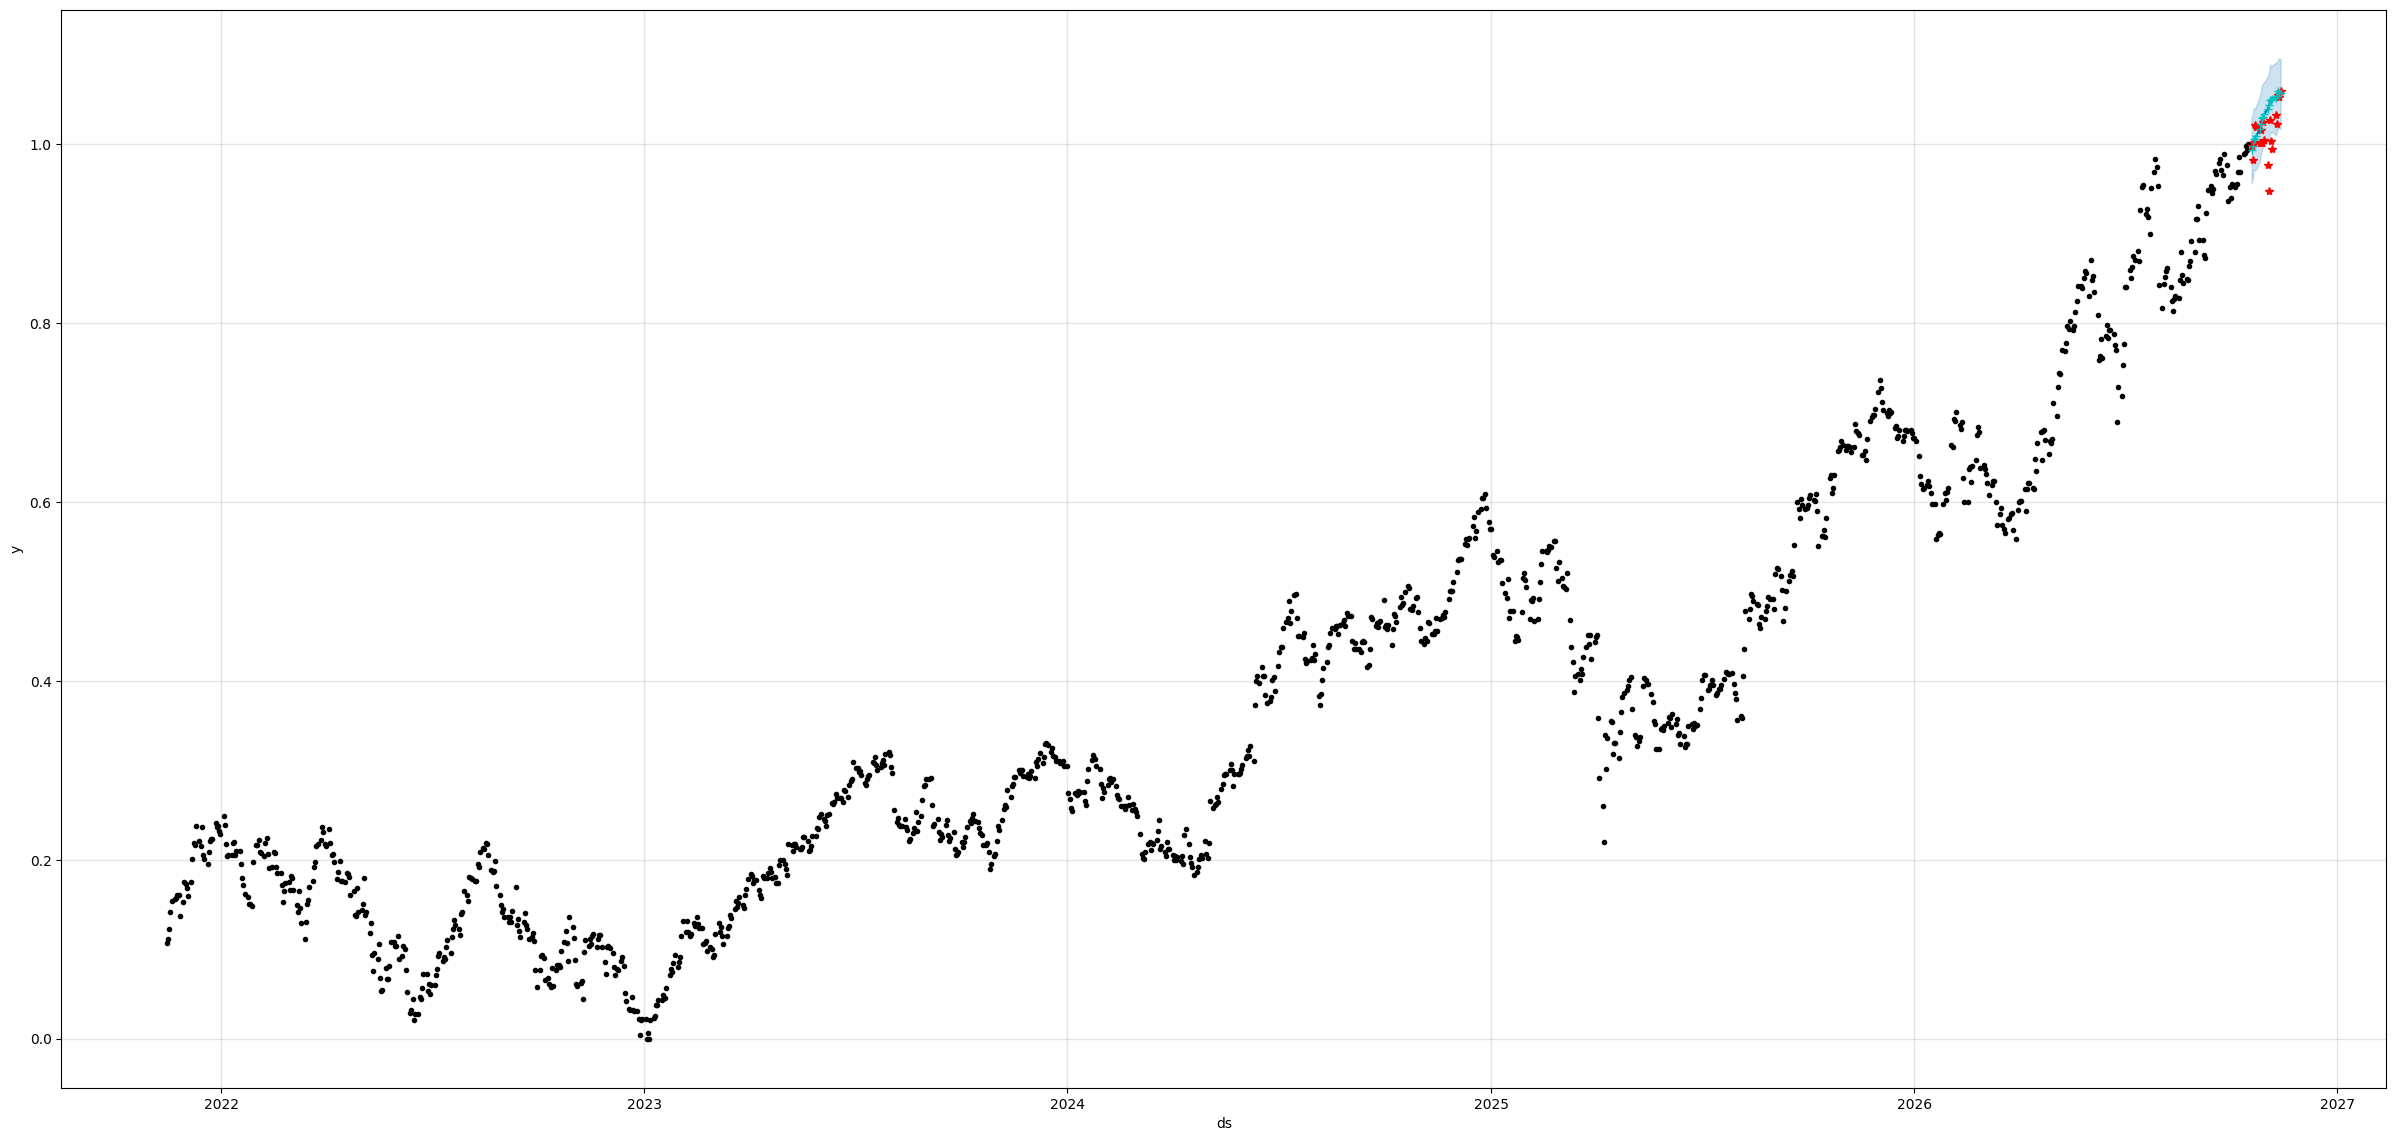

In [ ]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast_escalado = model_escalado.predict(test_escalado)

fig, ax = plt.subplots(figsize=(30, 14))
model_escalado.plot(forecast_escalado, ax=ax)       # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '*r') # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test_escalado['ds'], forecast_escalado['yhat'], '+c')  # Valores reales.

##<FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con lo obtenido en datos originales**

------------------------------------------------------------------------
La gráfica muestra que las predicciones de Prophet se mantienen por debajo de los valores reales durante gran parte del período de prueba, especialmente al final, cuando los precios presentan un aumento. Además, la banda de incertidumbre es bastante amplia. El RMSE obtenido fue de 0.034, superior al de ARIMA y al modelo ingenuo. Esto indica que Prophet tuvo dificultades para seguir la tendencia creciente de AAPL.

-----------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ESCALADOS**

In [ ]:
test_escalado.head()

,ds,y
1285,2026-10-19,0.997643
1286,2026-10-20,0.982052
1287,2026-10-21,1.002402
1288,2026-10-22,1.021574
1289,2026-10-23,1.019354


In [ ]:
df_temp_escalado.head()

,ds,y
0,2021-11-15,0.107380
1,2021-11-16,0.111808
2,2021-11-17,0.122832
3,2021-11-18,0.142223
4,2021-11-19,0.154088


In [ ]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date_escalado = '2026-09-11'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp_escalado, threshold_Date_escalado)

In [ ]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(32, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(64, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(1, activation='linear')
                                      ])
  return model

In [ ]:
def scheduler(epoch):
    if epoch <= 50:
        return 0.001
    elif epoch <= 100:
        return 0.0005
    elif epoch <= 150:
        return 0.0001
    else:
        return 0.00005

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - loss: 0.5436 - root_mean_squared_error: 0.7373 - val_loss: 0.9411 - val_root_mean_squared_error: 0.9701 - learning_rate: 0.0010
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.2914 - root_mean_squared_error: 0.5398 - val_loss: 0.7833 - val_root_mean_squared_error: 0.8850 - learning_rate: 0.0010
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.1587 - root_mean_squared_error: 0.3984 - val_loss: 0.6754 - val_root_mean_squared_error: 0.8218 - learning_rate: 0.0010
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0996 - root_mean_squared_error: 0.3156 - val_loss: 0.6041 - val_root_mean_squared_error: 0.7772 - learning_rate: 0.0010
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0796 - root_mean_squared_error: 0.2821 - val_loss: 0.5607 - val_root_mean_squared_error: 0.7488 - learning_rate: 0.0010
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0614 - root_mean_squared_error: 0.2478 

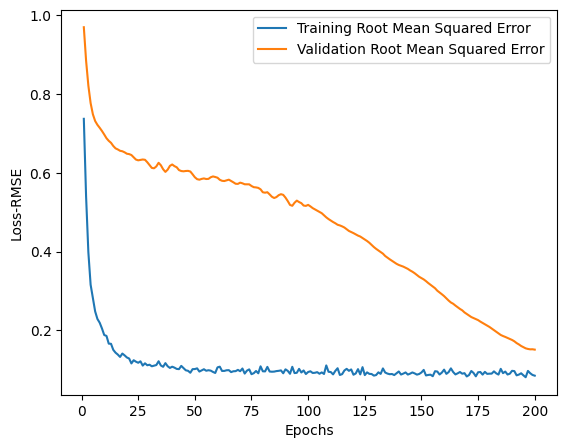

In [ ]:

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback, early_stop],

                       )



N = 0  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [ ]:
#pred_LSTM = H.model.predict(Test_X) scaled
pred_LSTM_escalado = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM_escalado.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step


(24,)

In [ ]:
# Calculamos el error RMSE con datos escalados:

pred_LSTM_escalado = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)

pred_LSTM_escalado = pred_LSTM_escalado.reshape(-1)[-20:]  # Select the last 20 values
rmse = np.sqrt(mean_squared_error(test_escalado['y'].values, pred_LSTM_escalado))

print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step

Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.156


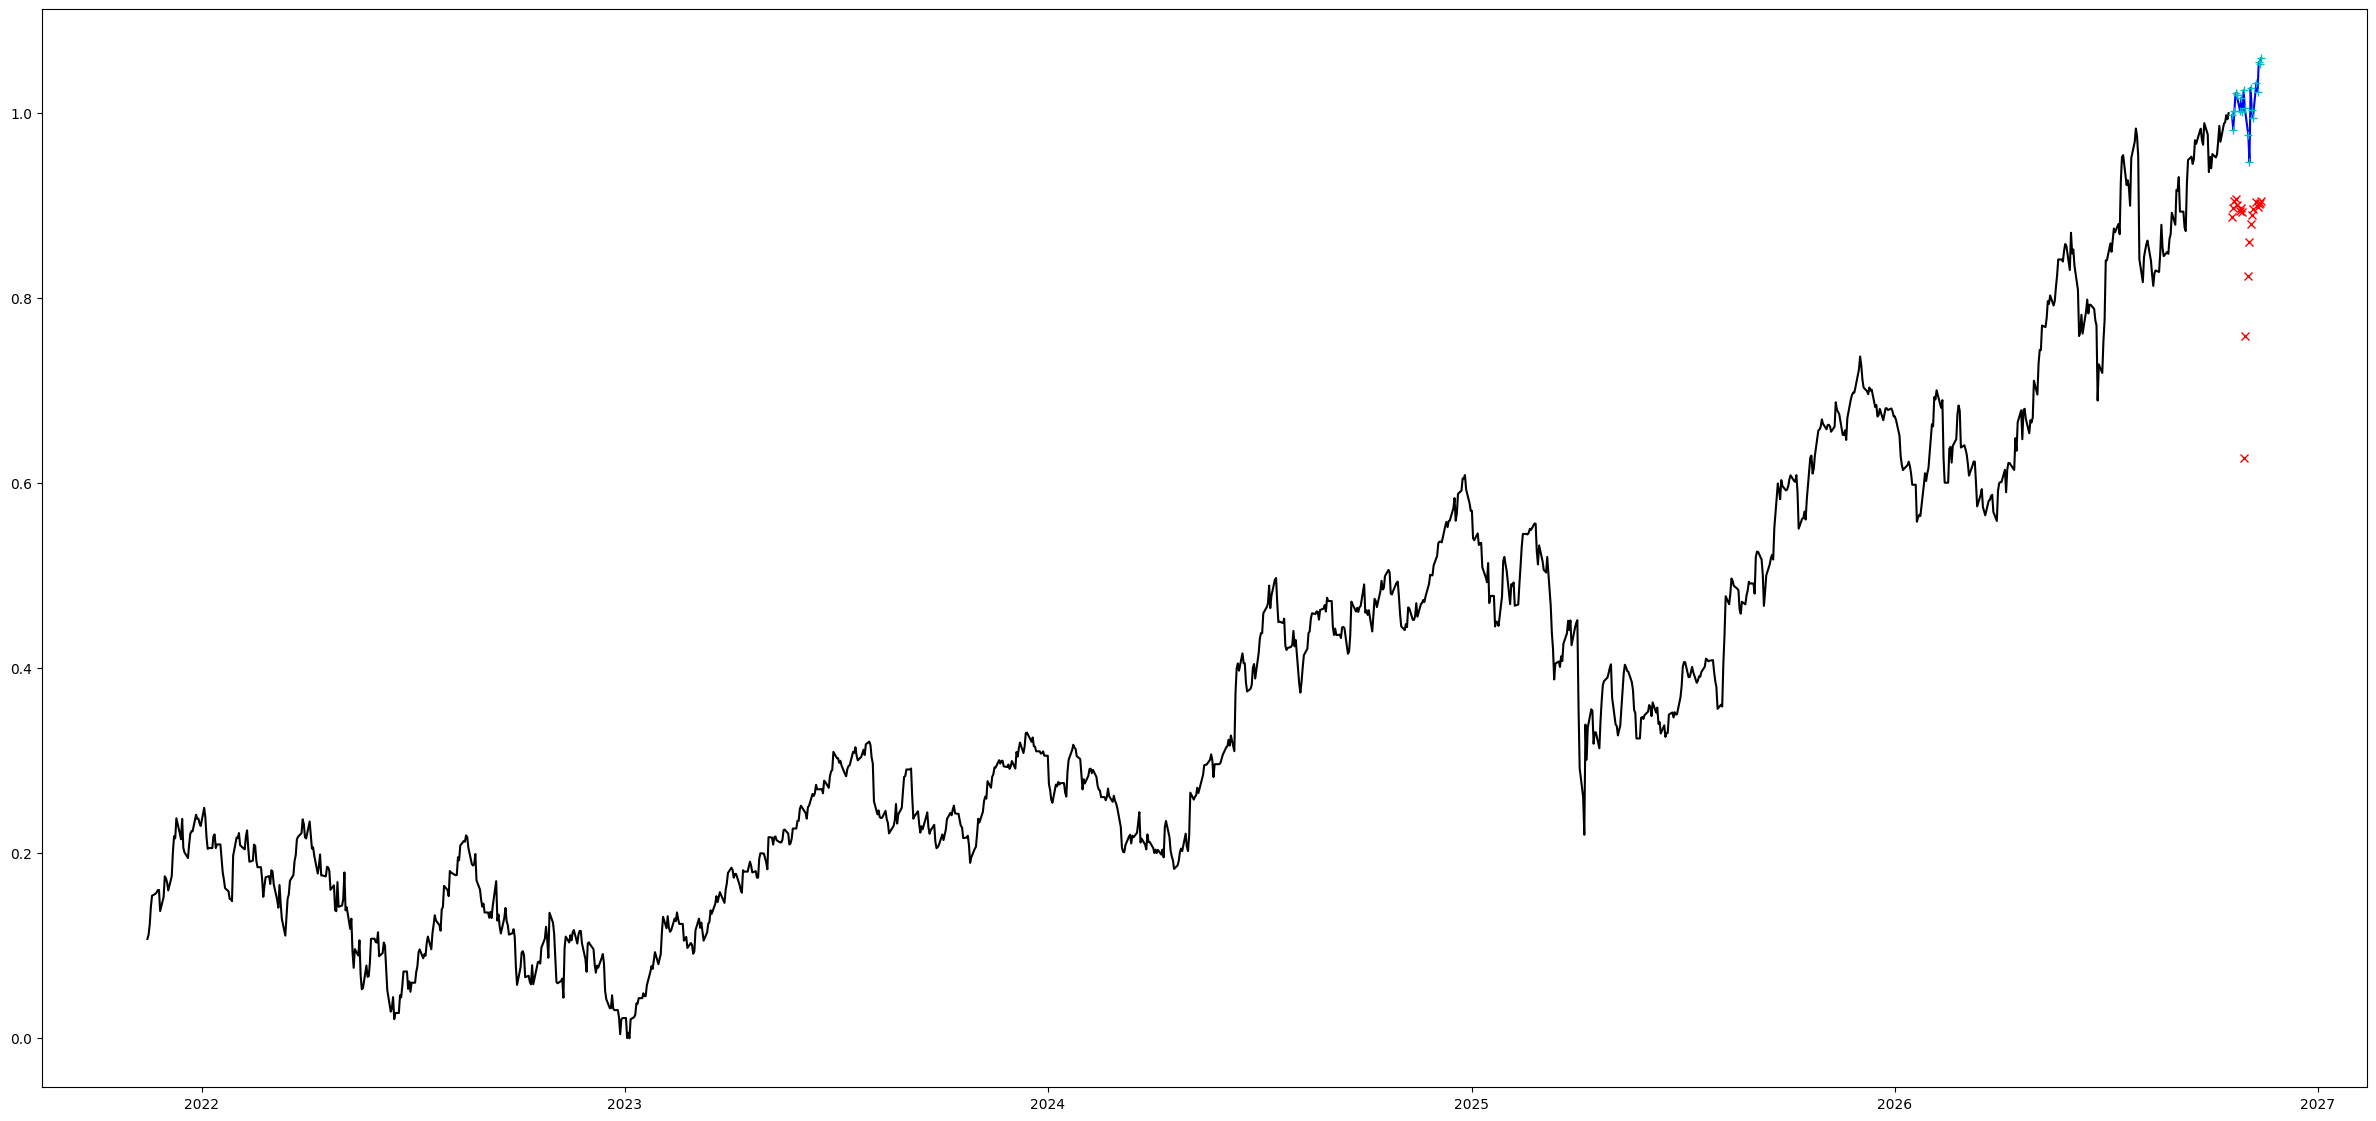

In [ ]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(30, 14))
ax = plt.plot(train_escalado['ds'], train_escalado['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], pred_LSTM_escalado, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en Datos Originales**

-----------------------------------------------------------------------------
En la gráfica se observa que las predicciones del LSTM (cruces rojas) se mantienen por debajo de los valores reales, sin lograr seguir la tendencia creciente de la serie. El RMSE obtenido fue de 0.156, lo que indica un error elevado. Esto demuestra que el escalamiento por sí solo no es suficiente para mejorar el modelo.
-----------------------------------------------------------------------------

# **CONCLUSIÓN DE LA ACTIVIDAD**


----------------------------------------------------------------------------
# **¿Consideras que el escalamiento de los datos ayude a obtener mejores predicciones? Justifica tu respuesta.**

No necesariamente. El uso de MinMaxScaler no significa que los modelos vayan a realizar mejores predicciones, ya que su función principal es ajustar los valores de los datos a un rango determinado. Esto puede facilitar el entrenamiento de algunos modelos, especialmente las redes neuronales como LSTM, pero no garantiza que disminuya el error de las predicciones.

### **Modelo Ingenuo**

RMSE original de 5.825 y escalado de 0.026. El escalamiento no representa una mejora en este modelo, ya que únicamente modifica la escala en la que se mide el error. Como el modelo solo utiliza el último valor registrado para realizar la siguiente predicción, su funcionamiento no cambia al escalar los datos.

### **Modelo ARIMA**

RMSE original de 6.265 y escalado de 0.031. Al igual que el modelo anterior, el escalamiento no modifica significativamente su capacidad para realizar predicciones. La diferencia entre ambos resultados se debe principalmente al cambio de escala de los datos.


### **Modelo Facebook-Meta-Prophet**

RMSE original de 9.139 y escalado de 0.034. Aunque el error cambia al trabajar con los datos escalados, esto no significa que el modelo haya mejorado. Prophet sigue presentando dificultades para representar correctamente la tendencia creciente de los precios de AAPL con los parámetros utilizados.

### **Modelo Long Short Term Memory (LSTM)**

RMSE original de 61.220 y escalado de 0.156. En este caso, el escalamiento tiene mayor importancia porque permite que la red neuronal trabaje con valores dentro de un rango más pequeño, lo que facilita su entrenamiento y ayuda a mantener la estabilidad durante el aprendizaje. Sin embargo, a pesar de este beneficio, sigue siendo el modelo con mayor error en comparación con los demás.

En general, los resultados muestran que el escalamiento facilita el procesamiento de los datos, principalmente para el LSTM, pero no garantiza que los modelos realicen predicciones más precisas.

A continación se muestra una tabla comparativa con los valores RMSE de datos originales y datos escalados de cada uno de los modelos:


| # | Modelo  | Datos Originales RMSE | Datos Escalados RMSE |
|---|---------|-----------------------|----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 5.825 | 0.026 |
| 2 | Modelo ARIMA | 6.265 | 0.031 |
| 3 | Modelo Facebook-Meta-Prophet | 9.139 | 0.034 |
| 4 | Long Short Term Memory (LSTM) | 61.220 | 0.156 |

------------------------------------------------------------------------
# **INTERPRETACION de resultados RMSE**


### **RMSE DATOS ORIGINALES**

Con los datos originales, el modelo ingenuo obtuvo el menor error (5.825), lo que indica que utilizar el último precio registrado como referencia fue suficiente para conseguir las predicciones más cercanas a los valores reales. ARIMA quedó en segundo lugar, con un RMSE de 6.265, mostrando un resultado bastante cercano al modelo ingenuo, aunque no consiguió superarlo.

Por otra parte, Prophet obtuvo un error de 9.139, lo que indica que tuvo mayores dificultades para seguir el comportamiento de los precios de Apple con los parámetros utilizados. Finalmente, LSTM presentó el error más alto, con 61.220. Esto refleja que el modelo tuvo problemas durante el entrenamiento y no logró representar adecuadamente el comportamiento de la serie, generando predicciones considerablemente alejadas de los valores reales.

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

### **RMSE DATOS ESCALADOS**

Al trabajar con los datos escalados al rango [0,1], se mantiene el mismo orden de resultados: el modelo ingenuo obtuvo el menor RMSE (0.026), seguido de ARIMA (0.031), Prophet (0.034) y finalmente LSTM (0.156).

Esto permite observar que el escalamiento no cambió el orden de desempeño de los modelos. Aunque facilita el entrenamiento de LSTM, este continúa presentando el mayor error en comparación con los demás. Por su parte, los modelos ingenuo y ARIMA mantienen resultados más favorables, mientras que Prophet sigue mostrando dificultades para ajustarse al comportamiento de los precios.


+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **En conclusión:**

El escalamiento mediante MinMaxScaler no garantiza que se obtengan mejores predicciones, pero sí ayuda a preparar los datos para que algunos modelos puedan trabajar con ellos de manera más estable. Esto es especialmente importante en LSTM, donde utilizar valores dentro de un rango de [0,1] facilita el proceso de entrenamiento. Sin embargo, los resultados demuestran que esto no es suficiente para conseguir una mayor precisión, ya que también depende de la arquitectura y los parámetros utilizados.

En el caso de los precios de AAPL, el modelo ingenuo y ARIMA obtuvieron los mejores resultados, mientras que Prophet y LSTM presentaron errores más elevados. Por lo tanto, se puede concluir que el escalamiento es principalmente una técnica de preparación de datos y no una garantía de mejora en los pronósticos. La precisión final depende de qué tan bien se adapte cada modelo al comportamiento de la serie temporal.

------------------------------------------------------------------------

# **Referencias Bibliográficas**

Norton, V. (2011). Adjusted closing prices. arXiv preprint arXiv:1105.2956.

Luo, Y. X., & Ji, Y. (2022, September). Prediction of the Stock Adjusted Closing Price Based On Improved PSO-LSTM Neural Network. In 2022 International Conference on Machine Learning and Cybernetics (ICMLC) (pp. 43-48). IEEE.

Wijaya, A. C., Kusumaningrum, R., Sugiharto, A., & Aryotejo, G. (2024, July). Prophet Algorithm Optimization with Particle Swarm Optimization for Adjusted Closing Price Forecasting in Xiaomi Corporation. In 2024 7th International Conference on Informatics and Computational Sciences (ICICoS) (pp. 376-381). IEEE.


----------------------------------------------------------------------------

>> ## **Fin del Ejercicio de Series de Tiempo**